In [1]:
from schedule import Schedule, Slot
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase
from evaluator import TSNConstraintEvaluator
from tsn_scheduling_problem import TSNScheduling
from env import TSNCandidateHopEnv
from benchmark_utils import build_network_generator_from_usecase, generate_one_arrival_stream, build_usecase_stream_from_request

In [28]:
problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("banana.json")

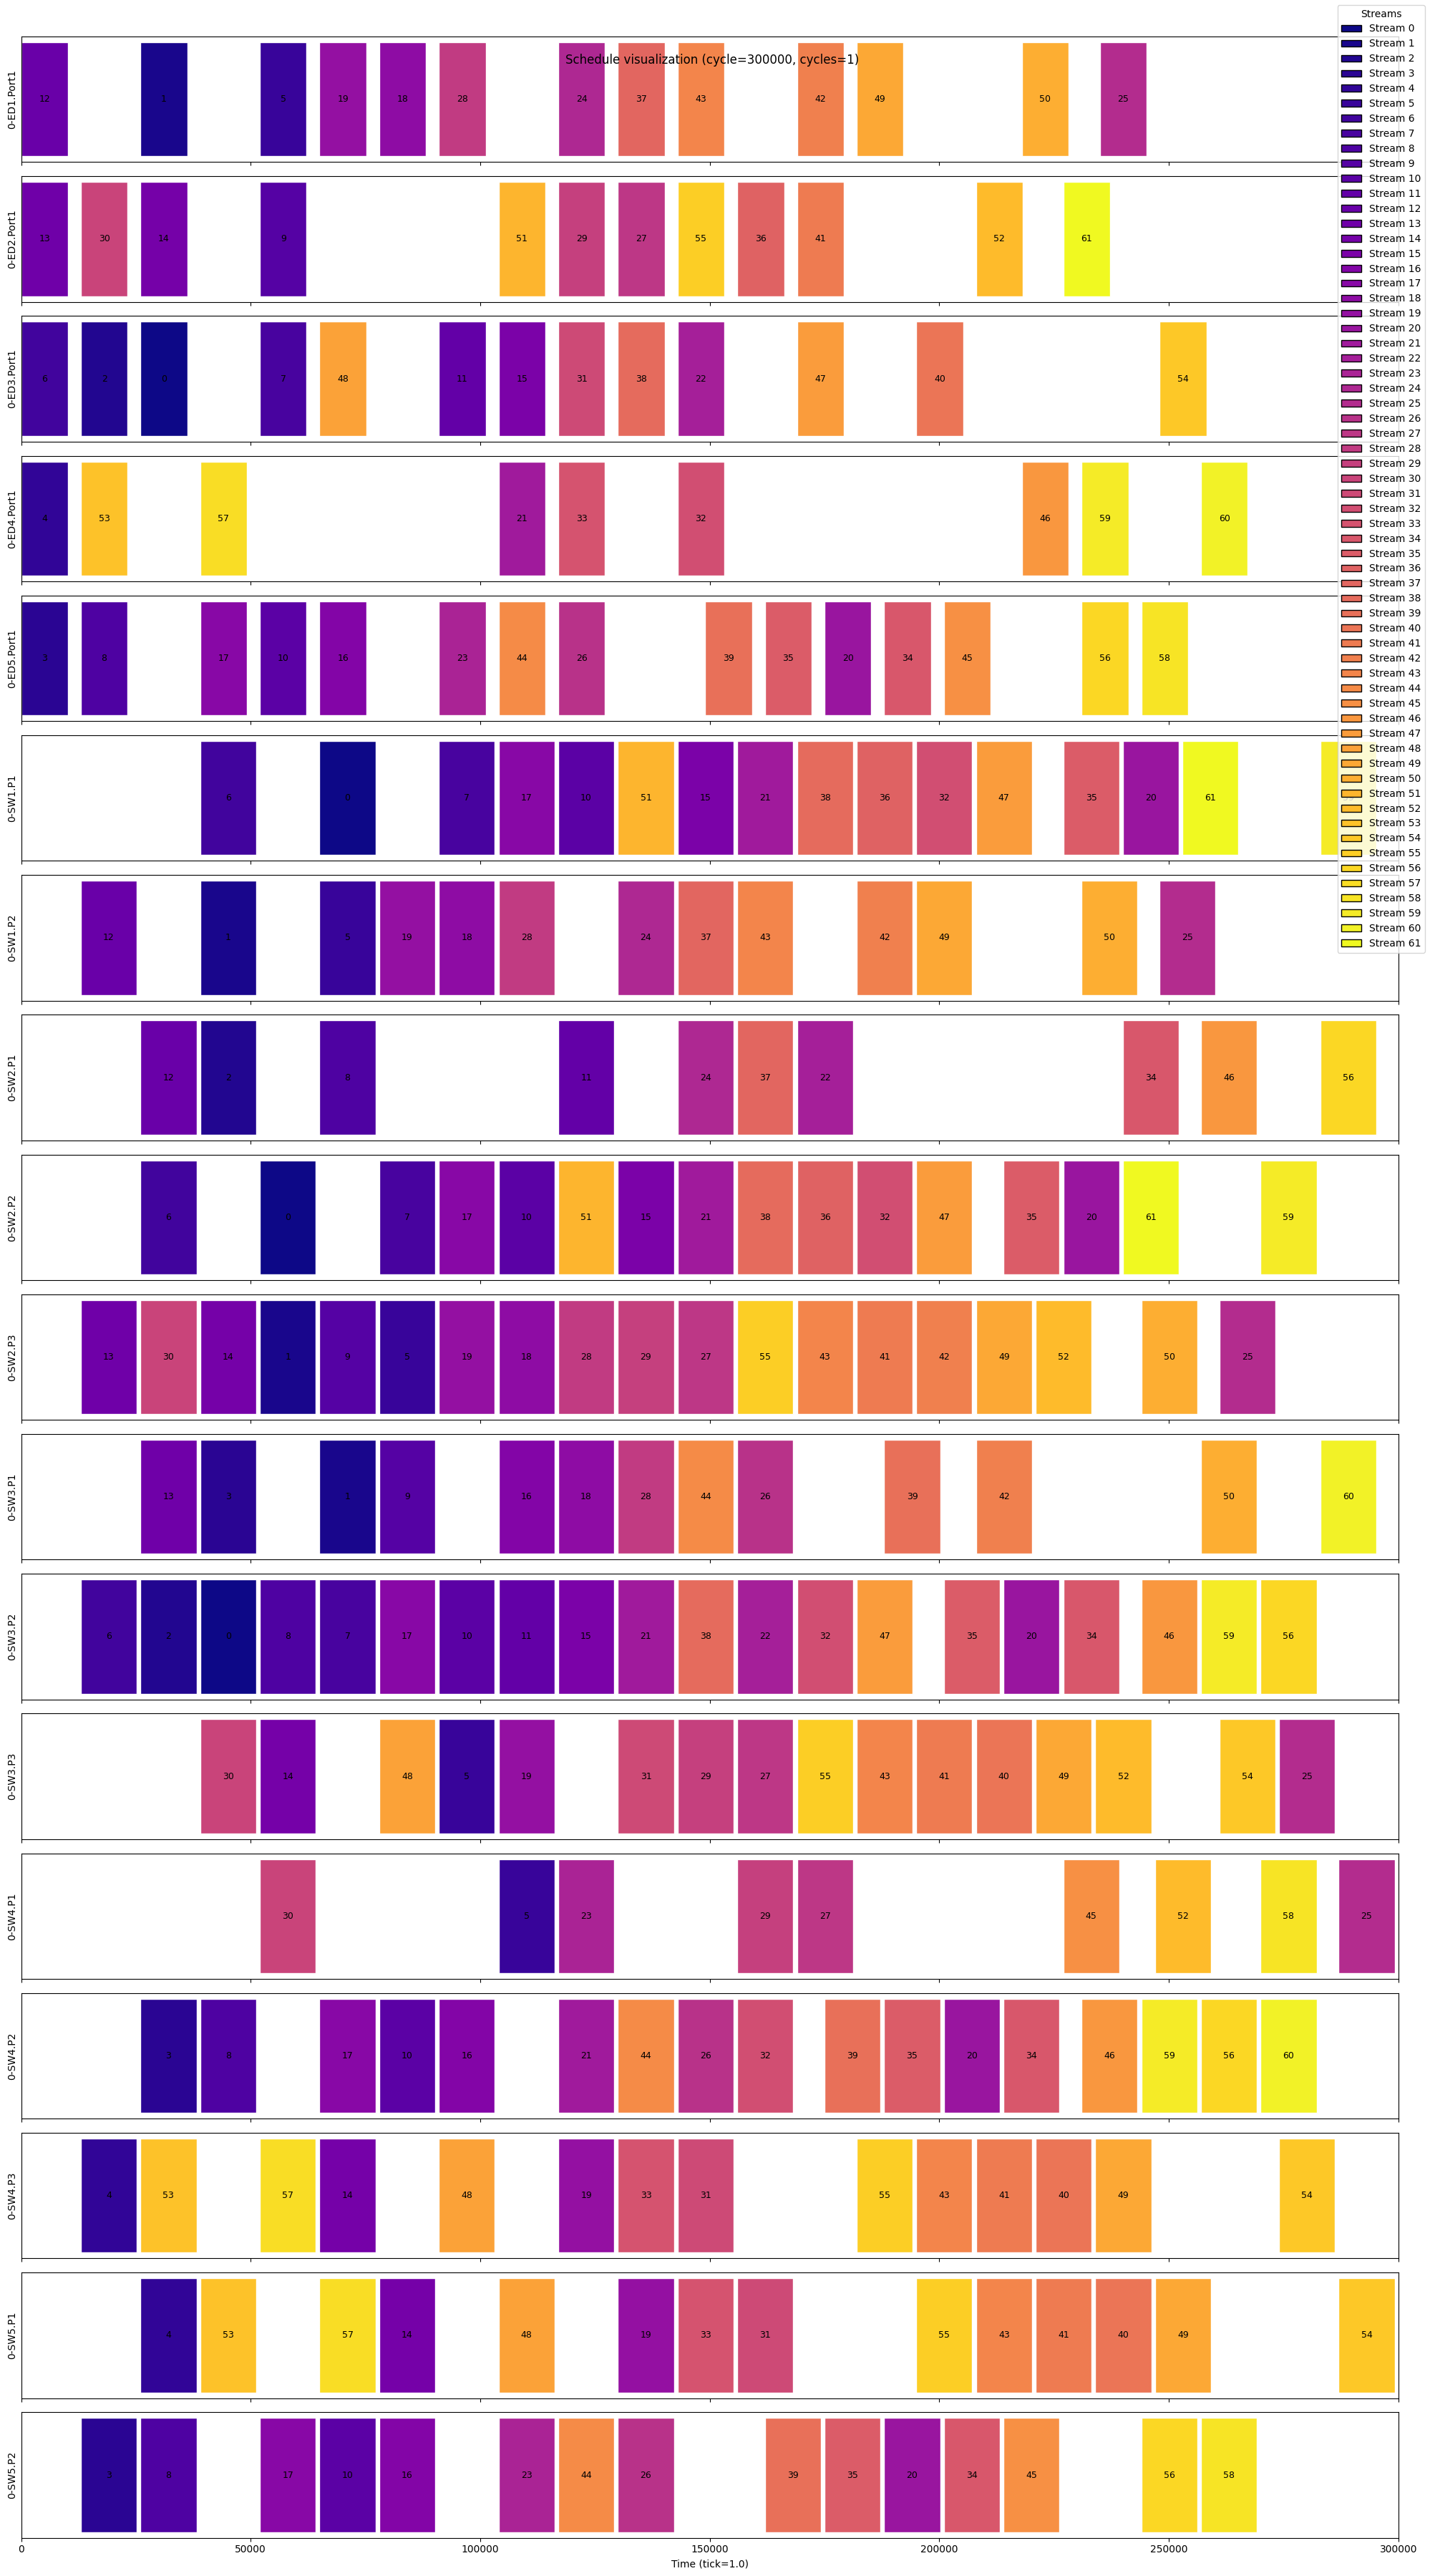

(<Figure size 2000x3600 with 18 Axes>,
 array([<Axes: ylabel='0-ED1.Port1'>, <Axes: ylabel='0-ED2.Port1'>,
        <Axes: ylabel='0-ED3.Port1'>, <Axes: ylabel='0-ED4.Port1'>,
        <Axes: ylabel='0-ED5.Port1'>, <Axes: ylabel='0-SW1.P1'>,
        <Axes: ylabel='0-SW1.P2'>, <Axes: ylabel='0-SW2.P1'>,
        <Axes: ylabel='0-SW2.P2'>, <Axes: ylabel='0-SW2.P3'>,
        <Axes: ylabel='0-SW3.P1'>, <Axes: ylabel='0-SW3.P2'>,
        <Axes: ylabel='0-SW3.P3'>, <Axes: ylabel='0-SW4.P1'>,
        <Axes: ylabel='0-SW4.P2'>, <Axes: ylabel='0-SW4.P3'>,
        <Axes: ylabel='0-SW5.P1'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='0-SW5.P2'>], dtype=object))

In [29]:
instance.schedule.plot(cycles=1, label = True)

In [11]:
import math
import random
import copy
import numpy as np


def generate_episode_trace(
    instance,
    arrivals_per_episode=100,
    lambda_arrival=0.1,
    mu_departure=0.05,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate one shared trace:
      - n_dep per step
      - raw arrival requests per step

    The trace is independent from the policy/benchmark.
    """
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))
    p_dep = 1.0 - math.exp(-mu_departure * dt)

    trace = []
    total_arrivals = 0

    # we need some estimate of active streams to sample n_dep;
    # use current active count of the reference instance and update
    # a simple counter proxy over time
    active_count = len({
        slot.stream_id for slot in instance.schedule
        if slot.stream_id is not None
    })

    while total_arrivals < arrivals_per_episode:
        # departures sampled from current proxy active_count
        n_dep = int(rng_np.binomial(active_count, p_dep)) if active_count > 0 else 0

        sampled_arrivals = int(rng_np.poisson(lambda_arrival))
        remaining = arrivals_per_episode - total_arrivals
        n_arr = min(sampled_arrivals, remaining)

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)
            total_arrivals += 1

        trace.append({
            "n_dep": n_dep,
            "arrivals": arrivals,
        })

        # update proxy active count for future sampling
        active_count = max(0, active_count - n_dep)
        active_count += sum(1 for a in arrivals if a is not None)

    return trace

In [12]:
import sched


def run_no_defrag_on_trace(
    instance,
    problem,
    trace,
    seed=42,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0
    total_dep = 0

    active_stream_ids = sorted({
        slot.stream_id for slot in sched
        if slot.stream_id is not None
    })

    stream_arrival_times = {
        int(sid): 0.0
        for sid in sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
    }

    for step in trace:
        step_count += 1

        # Departures
        active_stream_ids = sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(step["n_dep"], n_active)

        if n_dep > 0:
            res_del = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in res_del["removed_stream_ids"]:
                stream_arrival_times.pop(int(sid), None)

        # Arrivals
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=inst,
                problem=problem,
                port_intervals=port_intervals,
                max_candidates_per_hop=1,
                beam_width=1,
            )

            if result["accepted"]:
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
            else:
                rejected += 1
        total_dep += n_dep
        #print(f"Step {step_count}: Arrivals={len(step['arrivals'])}, Accepted={accepted}, Rejected={rejected}, Total Arrivals={total_arrivals}, Departures={n_dep}")

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    print(f"Total departures: {total_dep}")

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
    }

In [43]:
def run_of_ff_on_trace(
    instance,
    problem,
    trace,
    p=15,
    n=3,
    seed=42,
):
    import copy
    import random

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0
    departure_counter = 0

    # Real arrival-time tracker for active streams
    stream_arrival_times = {}

    # Seed currently active initial streams as time 0.0
    initial_active_stream_ids = sorted({
        int(slot.stream_id) for slot in sched
        if slot.stream_id is not None
    })
    for sid in initial_active_stream_ids:
        stream_arrival_times[int(sid)] = 0.0

    for step in trace:
        step_count += 1

        # -------------------------
        # Departures
        # -------------------------
        active_stream_ids = sorted({
            int(slot.stream_id) for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(int(step["n_dep"]), n_active)

        if n_dep > 0:
            dep_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            removed_ids = dep_result.get("removed_stream_ids", [])
            for sid in removed_ids:
                stream_arrival_times.pop(int(sid), None)

            departure_counter += int(n_dep)

            # Trigger OF-FF after departures
            sched.oldest_first_first_fit_defrag(
                usecase=inst,
                problem=problem,
                p=p,
                n=n,
                departure_counter=departure_counter,
                queue_id=5,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=inst,
                problem=problem,
                port_intervals=port_intervals,
                max_candidates_per_hop=1,
                beam_width=1,
            )

            if result["accepted"]:
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
            else:
                rejected += 1

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    if n==0:
         defrag_cycles = 0
         reallocations = 0
    else:
        defrag_cycles = departure_counter // p
        reallocations = defrag_cycles * n

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
        "departures": departure_counter,
        "defrag_cycles": defrag_cycles,
        "reallocations": reallocations,
    }

In [14]:
import copy
import random
import numpy as np
import torch

from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def run_drl_on_trace(
    model_path,
    instance,
    problem,
    trace,
    seed=42,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
    debug_drl=False,
    debug_max_actions=50,
):
    """
    Replay one shared arrival/departure trace using the DRL policy.

    IMPORTANT:
    - Benchmark horizon is controlled by the trace (typically 100 arrivals),
      NOT by env decision_points_per_episode.
    - We use the env only for:
        * candidate generation
        * observations
        * applying reallocation actions
    - We do NOT use the env's internal arrival/departure simulator.

    Trace format:
        [
          {"n_dep": int, "arrivals": [raw_stream_or_None, ...]},
          ...
        ]
    """
    rng_py = random.Random(seed)
    instance = copy.deepcopy(instance)

    # Build a fresh env, but we will bypass its internal simulator loop.
    env = TSNCandidatePathEnv(
        problem=problem,
        usecase=instance,
        useless_gap_threshold_bytes=useless_gap_threshold_bytes,
        expected_incoming_bytes=expected_incoming_bytes,
        invalid_penalty=invalid_penalty,
        max_candidates=max_candidates,
        max_steps=max_steps,
        max_hops=max_hops,
        init_from_usecase_schedule=init_from_usecase_schedule,
        include_current_offset_candidate=include_current_offset_candidate,
        per_hop_candidate_limit=per_hop_candidate_limit,
        beam_width=beam_width,
        defrag_cycle_penalty=defrag_cycle_penalty,
        reallocation_penalty=reallocation_penalty,
        ed_ed_settings=None,
        top_k_oldest_random=top_k_oldest_random,
        seed=seed,
    )

    model = DQN.load(model_path, env=env)

    # Do NOT call reset(), but manually load the initial schedule.
  
    #obs, info = env.reset(seed=seed)
    env._rebuild_runtime_metadata()

    loaded = False
    if init_from_usecase_schedule:
        loaded = env._create_initial_schedule_from_usecase()

    if not loaded:
        env._create_fallback_initial_schedule()

    env._sync_usecase_schedule()
    env._sync_evaluator_with_schedule_durations()
    env._backup_current_as_last_valid()


    # After reset(), the training env may already have advanced internally.
    # For benchmarking on a shared trace, overwrite runtime counters and state semantics.
    env.blocked_requests = 0
    env.total_requests = 0
    env.accepted_requests = 0
    env.current_time = 0.0

    env.episode_invalid_moves = 0
    env.episode_violation_sum = 0
    env.episode_decision_points = 0
    env.episode_reallocations = 0
    env.episode_defrag_cycles = 0

    env.decision_active = False
    env.in_defrag_cycle = False
    env.decision_stream_order = []
    env.decision_pointer = 0
    env.current_candidates = []

    debug_action_counter = 0

    # Initial streams are present from the starting schedule.
    # Keep their "arrival times" at 0.0 for age ordering.
    env.stream_arrival_times = {int(sid): 0.0 for sid in env._active_stream_ids()}

    step_count = 0

    for step in trace:
        step_count += 1
        env.current_time += 1.0

        # --------------------------------------------------
        # 1) Departures from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        active_stream_ids = sorted({
            int(slot.stream_id) for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(int(step["n_dep"]), n_active)

        if n_dep > 0:
            before_ids = list(active_stream_ids)

            sched.delete_streams(
                n_remove=n_dep,
                usecase=env.usecase,
                rng=rng_py,
                port_intervals=env.port_intervals,
                stream_arrival_times=env.stream_arrival_times,
            )

            env._load_state_from_schedule(sched)

            after_ids = env._active_stream_ids()
            removed_ids = env._removed_stream_ids(before_ids, after_ids)
            for sid in removed_ids:
                env.stream_arrival_times.pop(int(sid), None)

            # One decision point occurs because this trace step had departures.
            env.episode_decision_points += 1

            # --------------------------------------------------
            # 2) Let DRL act until STOP or focus list exhausted
            # --------------------------------------------------
            has_decision = env._begin_decision_point()

            if has_decision:
                # We do NOT call env.step(0) because STOP there would trigger
                # the training env's internal simulator advance. Instead, we
                # manually emulate "decision logic only".
                while env.decision_active:
                    obs = env._get_obs()

                    action, _ = model.predict(obs, deterministic=deterministic)
                    action = int(np.asarray(action).item())

                    # -------------------------------
                    # DRL DEBUG: action + Q-values
                    # -------------------------------
                    if debug_drl and debug_action_counter < debug_max_actions:
                        with torch.no_grad():
                            obs_tensor, _ = model.policy.obs_to_tensor(obs)
                            q_values = model.q_net(obs_tensor)
                            q_values = q_values.cpu().numpy()[0]

                        mask = obs["candidate_mask"]
                        mask = np.asarray(mask).reshape(-1)

                        available_actions = np.where(mask > 0)[0]
                        n_candidates_available = max(0, len(available_actions) - 1)

                        print("\n[DRL DEBUG]")
                        print(f"Trace step              : {step_count}")
                        print(f"Current time            : {env.current_time}")
                        print(f"Decision pointer        : {env.decision_pointer}/{len(env.decision_stream_order)}")
                        print(f"Focus stream            : {getattr(env.focus, 'stream_id', None)}")
                        print(f"Available actions       : {available_actions.tolist()}")
                        print(f"Candidates available    : {n_candidates_available}")
                        print(f"Chosen action           : {action}")
                        print(f"STOP Q-value            : {q_values[0]:.6f}")

                        for a in available_actions:
                            label = "STOP" if a == 0 else f"CAND {a-1}"
                            print(f"Action {a:2d} ({label:7s}) | Q={q_values[a]: .6f}")

                        debug_action_counter += 1

                    # Padding -> STOP
                    if action > 0:
                        cand_idx = action - 1
                        if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                            action = 0

                    # STOP: end only the current decision point (no internal sim advance)
                    if action == 0:
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : STOP")
                            print("Reward after action     : 0.000000  # manual benchmark STOP")
                            print(f"Reallocations so far    : {env.episode_reallocations}")
                            print(f"Defrag cycles so far    : {env.episode_defrag_cycles}")

                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    # Candidate application branch (mirrors env.step logic,
                    # but without calling _finish_decision_point_and_continue()).
                    cand_idx = action - 1
                    chosen_candidate = env.current_candidates[cand_idx]

                    saved_ports = copy.deepcopy(env.port_schedules)
                    saved_offsets = copy.deepcopy(env.stream_offsets)

                    applied = env._apply_stream_move(
                        chosen_candidate.stream_id,
                        chosen_candidate.offsets,
                    )

                    if not applied:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : INVALID / NOT APPLIED")
                            print(f"Reward after action     : {-float(invalid_penalty):.6f}")
                        break

                    violation_sum = env._violation_sum()
                    env.episode_violation_sum += int(violation_sum)

                    if violation_sum != 0:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : INVALID / VIOLATION")
                            print(f"Violation sum           : {violation_sum}")
                            print(f"Reward after action     : {-float(invalid_penalty):.6f}")
                        break

                    # Valid reallocation
                    env._backup_current_as_last_valid()
                    env.episode_reallocations += 1
                    debug_reward = -float(reallocation_penalty)

                    if not env.in_defrag_cycle:
                        env.in_defrag_cycle = True
                        env.episode_defrag_cycles += 1
                        debug_reward -= float(defrag_cycle_penalty)

                    # Move to next focus stream within this decision point
                    env._advance_stream_focus()

                    if env.decision_pointer >= len(env.decision_stream_order):
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    env.current_candidates = env._candidate_list_for_stream(
                        int(env.focus.stream_id)
                    )

                    if debug_drl and debug_action_counter <= debug_max_actions:
                        print("Applied action          : REALLOCATION")
                        print(f"Moved stream            : {chosen_candidate.stream_id}")
                        print(f"New offsets             : {chosen_candidate.offsets}")
                        print(f"Violation sum           : {violation_sum}")
                        print(f"Reward after action     : {debug_reward:.6f}  # penalty-only proxy")
                        print(f"Reallocations so far    : {env.episode_reallocations}")
                        print(f"Defrag cycles so far    : {env.episode_defrag_cycles}")

        # --------------------------------------------------
        # 3) Arrivals from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        for raw_stream in step["arrivals"]:
            env.total_requests += 1

            if raw_stream is None:
                env.blocked_requests += 1
                continue

            stream_id = len(env.usecase.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                env.usecase,
                k_paths=1,
            )
            if stream is None:
                env.blocked_requests += 1
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=env.usecase,
                problem=env.problem,
                port_intervals=env.port_intervals,
                max_candidates_per_hop=10,
                beam_width=10,
            )

            env._rebuild_runtime_metadata()

            accepted_ids = result.get("accepted", [])

            if accepted_ids:
                env.accepted_requests += 1
                new_sid = int(accepted_ids[-1])
                env.stream_arrival_times[new_sid] = float(env.current_time)
            else:
                env.blocked_requests += 1

            env._load_state_from_schedule(sched)

    total_arrivals = int(env.total_requests)
    rejections = int(env.blocked_requests)
    accepted = int(env.accepted_requests)

    sbr = rejections / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    result = {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "steps": int(step_count),
        "accepted": accepted,
        "rejected": rejections,
        "arrivals": total_arrivals,
        "decision_points": int(env.episode_decision_points),
        "invalid_moves": int(env.episode_invalid_moves),
        "reallocations": int(env.episode_reallocations),
        "defrag_cycles": int(env.episode_defrag_cycles),
    }

    env.close()
    return result

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [15]:
import copy
def benchmark_shared_trace(
    methods,
    instance,
    problem,
    n_episodes=10,
    arrivals_per_episode=100,
    lambda_arrival=0.1,
    mu_departure=0.05,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
    model_path=None,
    p=15,
    n=3,
    p2=10,
    n2=5,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
    debug_drl=True,
    debug_max_actions=30,
):
    """
    Flexible shared-trace benchmark.

    methods: tuple/list containing any of:
        - "no_defrag"
        - "of_ff"
        - "of_ff2"
        - "drl"

    Returns dict with arrays for requested methods only.
    """

    methods = tuple(methods)
    valid_methods = {"no_defrag", "of_ff", "of_ff2", "drl"}
    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid: {valid_methods}")

    if "drl" in methods and model_path is None:
        raise ValueError("model_path must be provided when 'drl' is requested.")

    results = {}

    # initialize storage only for requested methods
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_steps"] = []

        if m in ("of_ff", "of_ff2", "drl"):
            results[f"{m}_reallocations"] = []
            results[f"{m}_defrag_cycles"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_episode_trace(
            instance=instance,
            arrivals_per_episode=arrivals_per_episode,
            lambda_arrival=lambda_arrival,
            mu_departure=mu_departure,
            dt=dt,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        episode_msg = [f"Episode {ep}:"]

        if "no_defrag" in methods:
            res_no = run_no_defrag_on_trace(
                instance=copy.deepcopy(instance),
                problem=problem,
                trace=trace,
                seed=ep_seed,
            )
            results["no_defrag_sbr"].append(res_no["sbr"])
            results["no_defrag_acc"].append(res_no["acceptance"])
            results["no_defrag_steps"].append(res_no["steps"])
            episode_msg.append(f"No-Defrag={res_no['sbr']:.4f}")

        if "of_ff" in methods:
            res_ff = run_of_ff_on_trace(
                instance=copy.deepcopy(instance),
                problem=problem,
                trace=trace,
                p=p,
                n=n,
                seed=ep_seed,
            )
            results["of_ff_sbr"].append(res_ff["sbr"])
            results["of_ff_acc"].append(res_ff["acceptance"])
            results["of_ff_steps"].append(res_ff["steps"])
            results["of_ff_reallocations"].append(res_ff["reallocations"])
            results["of_ff_defrag_cycles"].append(res_ff["defrag_cycles"])
            episode_msg.append(f"OF-FF={res_ff['sbr']:.4f}")

        if "of_ff2" in methods:
            res_ff2 = run_of_ff_on_trace(
                instance=copy.deepcopy(instance),
                problem=problem,
                trace=trace,
                p=p2,
                n=n2,
                seed=ep_seed,
            )
            results["of_ff2_sbr"].append(res_ff2["sbr"])
            results["of_ff2_acc"].append(res_ff2["acceptance"])
            results["of_ff2_steps"].append(res_ff2["steps"])
            results["of_ff2_reallocations"].append(res_ff2["reallocations"])
            results["of_ff2_defrag_cycles"].append(res_ff2["defrag_cycles"])
            episode_msg.append(f"OF-FF2={res_ff2['sbr']:.4f}")

        if "drl" in methods:
            res_drl = run_drl_on_trace(
                model_path=model_path,
                instance=copy.deepcopy(instance),
                problem=problem,
                trace=trace,
                seed=ep_seed,
                max_candidates=max_candidates,
                max_steps=max_steps,
                max_hops=max_hops,
                init_from_usecase_schedule=init_from_usecase_schedule,
                include_current_offset_candidate=include_current_offset_candidate,
                per_hop_candidate_limit=per_hop_candidate_limit,
                beam_width=beam_width,
                defrag_cycle_penalty=defrag_cycle_penalty,
                reallocation_penalty=reallocation_penalty,
                invalid_penalty=invalid_penalty,
                useless_gap_threshold_bytes=useless_gap_threshold_bytes,
                expected_incoming_bytes=expected_incoming_bytes,
                top_k_oldest_random=top_k_oldest_random,
                deterministic=deterministic,
                debug_drl=debug_drl,
                debug_max_actions=debug_max_actions,
            )
            results["drl_sbr"].append(res_drl["sbr"])
            results["drl_acc"].append(res_drl["acceptance"])
            results["drl_steps"].append(res_drl["steps"])
            results["drl_reallocations"].append(res_drl["reallocations"])
            results["drl_defrag_cycles"].append(res_drl["defrag_cycles"])
            episode_msg.append(
                f"DRL={res_drl['sbr']:.4f} "
                f"| realloc={res_drl['reallocations']} "
                f"| cycles={res_drl['defrag_cycles']}"
            )

        print(" | ".join(episode_msg))

    # convert lists to numpy arrays
    for k in list(results.keys()):
        dtype = float if ("_sbr" in k or "_acc" in k) else int
        results[k] = np.array(results[k], dtype=dtype)

    return results

In [16]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_sbr_curves(curves, smooth_window=None):
    """
    curves: dict like
    {
        "No-Defrag": sbr_values,
        "Heuristic-A": other_values,
        ...
    }
    """

    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    for i, (label, values) in enumerate(curves.items()):
        y = np.asarray(values, dtype=float)
        x = np.arange(len(y))

        if smooth_window is not None and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode="same")

        style = styles[i % len(styles)]

        plt.plot(
            x, y,
            label=label,
            linewidth=1.2,
            **style
        )

    plt.ylim(0.02, 0.20)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Service Blocking Ratio (SBR)", fontsize=12)
    
    n = len(y)
    plt.xlim(0, n - 1)
    plt.margins(x=0)

    ticks = list(range(0, n, 1))
    if (n - 1) not in ticks:
        ticks.append(n - 1)

    # Replace last tick label with n instead of n-1
    labels = [str(t) for t in ticks]
    labels[-1] = str(n)

    plt.xticks(ticks, labels)
    #plt.grid(True, alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [17]:
import matplotlib.pyplot as plt
import numpy as np


def _smooth_values(values, smooth_window=None):
    y = np.asarray(values, dtype=float)

    if smooth_window is not None and smooth_window > 1:
        kernel = np.ones(smooth_window) / smooth_window
        y = np.convolve(y, kernel, mode="same")

    return y


def plot_multiple_curves(
    curves,
    ylabel,
    title,
    smooth_window=None,
    ylim=None,
):
    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    max_n = 0

    for i, (label, values) in enumerate(curves.items()):
        y = _smooth_values(values, smooth_window)
        x = np.arange(len(y))
        max_n = max(max_n, len(y))

        style = styles[i % len(styles)]

        plt.plot(
            x,
            y,
            label=label,
            linewidth=1.2,
            **style
        )

    if ylim is not None:
        plt.ylim(*ylim)

    plt.xlabel("Episode", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.title(title)

    if max_n > 0:
        plt.xlim(0, max_n - 1)
        plt.margins(x=0)

        ticks = list(range(0, max_n, 1))
        if (max_n - 1) not in ticks:
            ticks.append(max_n - 1)

        labels = [str(t) for t in ticks]
        labels[-1] = str(max_n)

        plt.xticks(ticks, labels)

    plt.legend()
    plt.tight_layout()
    plt.show()

In [44]:
results = benchmark_shared_trace(
    methods=("no_defrag","of_ff"),
    model_path="run_22/best_model.zip",
    instance=instance,
    problem=problem,
    n_episodes=3,
    arrivals_per_episode=20,
    lambda_arrival=1,
    mu_departure=0.2,
    seed=42,
    p=10,
    n=4,
    max_steps=500,
    deterministic=True,
    debug_drl=False,
    debug_max_actions=10,
)


Total departures: 73
Episode 0: | No-Defrag=0.3000 | OF-FF=0.3000
Total departures: 72
Episode 1: | No-Defrag=0.2000 | OF-FF=0.3000
Total departures: 75
Episode 2: | No-Defrag=0.2500 | OF-FF=0.2500


In [39]:
print("wassim")

wassim


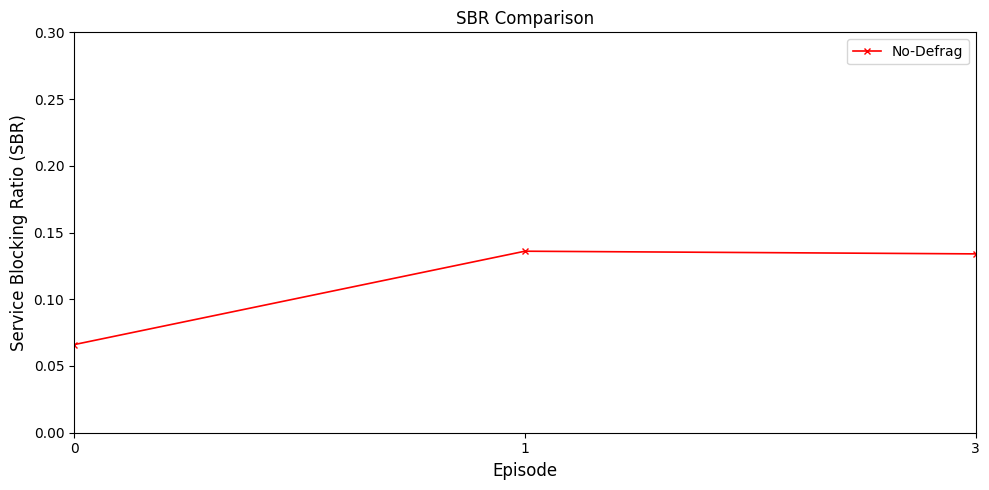

In [40]:


# 1) SBR curves
sbr_curves = {}

if "no_defrag_sbr" in results:
    sbr_curves["No-Defrag"] = results["no_defrag_sbr"]

if "of_ff_sbr" in results:
    sbr_curves["OF-FF"] = results["of_ff_sbr"]

if "of_ff2_sbr" in results:
    sbr_curves["OF-FF2"] = results["of_ff2_sbr"]

if "drl_sbr" in results:
    sbr_curves["DRL"] = results["drl_sbr"]

plot_multiple_curves(
    sbr_curves,
    ylabel="Service Blocking Ratio (SBR)",
    title="SBR Comparison",
    smooth_window=2,
    ylim=(0.0, 0.3),
)

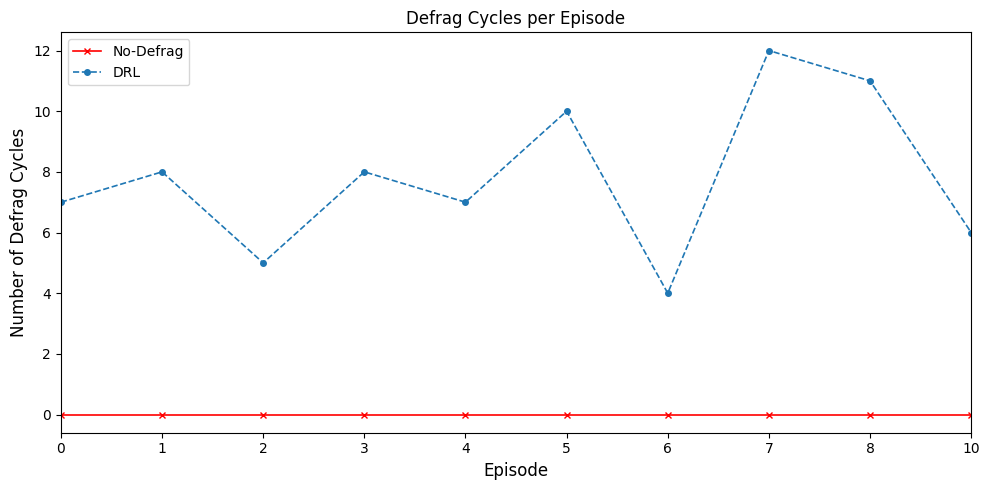

In [14]:
n_episodes = len(results["no_defrag_sbr"])
defrag_curves = {}

if "no_defrag_sbr" in results:
    defrag_curves["No-Defrag"] = np.zeros(n_episodes)

if "of_ff_defrag_cycles" in results:
    defrag_curves["OF-FF"] = results["of_ff_defrag_cycles"]

if "of_ff2_defrag_cycles" in results:
    defrag_curves["OF-FF2"] = results["of_ff2_defrag_cycles"]

if "drl_defrag_cycles" in results:
    defrag_curves["DRL"] = results["drl_defrag_cycles"]

plot_multiple_curves(
    defrag_curves,
    ylabel="Number of Defrag Cycles",
    title="Defrag Cycles per Episode",
    smooth_window=None,
)

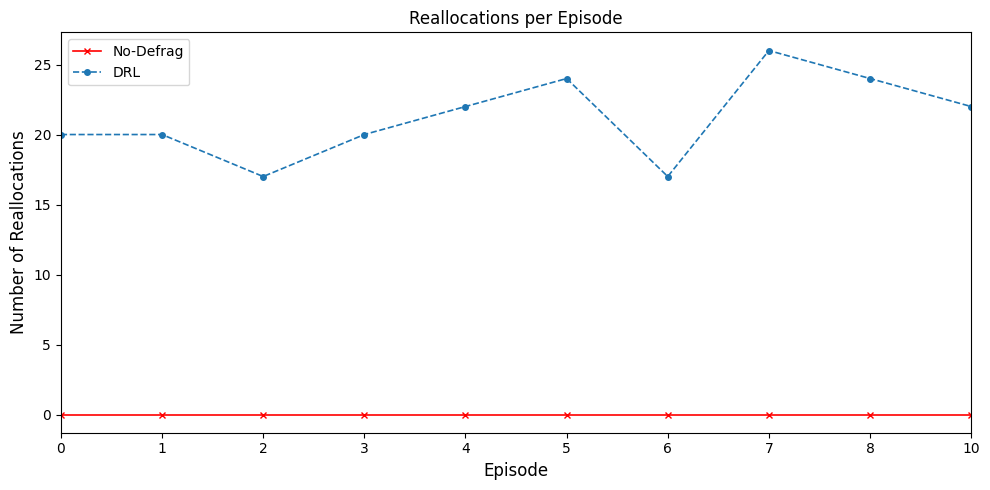

In [15]:
realloc_curves = {}
n_episodes = len(results["no_defrag_sbr"])

if "no_defrag_sbr" in results:
    realloc_curves["No-Defrag"] = np.zeros(n_episodes)

if "of_ff_reallocations" in results:
    realloc_curves["OF-FF"] = results["of_ff_reallocations"]

if "of_ff2_reallocations" in results:
    realloc_curves["OF-FF2"] = results["of_ff2_reallocations"]

if "drl_reallocations" in results:
    realloc_curves["DRL"] = results["drl_reallocations"]

plot_multiple_curves(
    realloc_curves,
    ylabel="Number of Reallocations",
    title="Reallocations per Episode",
    smooth_window=0,
)

In [132]:
print(results2["of_ff_reallocations"])

[690 720 720 705 705 720 690 735 705 720 705 735 690 705 720 720 705 720
 705 690]


In [ ]:
curves = {}

label_map = {
    "no_defrag_sbr": "No-Defrag",
    "drl_sbr": "DRL",
}

for key, label in label_map.items():
    if key in results2:
        curves[label] = results2[key]

plot_multiple_sbr_curves(curves, smooth_window=2)